In [1]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os
import cmath 
import json
import seaborn as sns
from collections import Counter
from scipy.stats import linregress


In [2]:
data = pd.read_csv("données/LucasBenjamin_684432bf9acc38d54321fc04.csv", skiprows=1, index_col=3)
data

,rt,url,trial_type,time_elapsed,internal_node_id,success,responses,view_history,trial_rt,response_rts,stimulus,presented_angles,stimulus_rotations,key_press,final_angle,confidence,target,score,correct
trial_index,,,,,,,,,,,,,,,,,,,
0,72492.0,external-consent.html,external-html,72692,0.0-0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,fullscreen,78581,0.0-1.0,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,12150.0,NaN,survey-dropdown,90750,0.0-2.0,NaN,"{""0"":""18-25"",""1"":""M""}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,17536.0,NaN,survey-text,108295,0.0-3.0,NaN,"{""Q0"":""684432bf9acc38d54321fc04""}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,56654.0,NaN,instructions,164950,0.0-4.0,NaN,NaN,"[{""page_index"":0,""viewing_time"":12674},{""page_...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
335,NaN,NaN,lb-SeqAns-visual,3158925,0.0-224.0,NaN,NaN,NaN,2167.0,NaN,Stims/Gabor_img/Gabor_0.png,"8.4713010053,-6.9664267772,-28.9437046841,14.4...","0,45,45,0,0,45,0",NaN,228.221040,0.0,25.791335,4.0,NaN
336,NaN,NaN,lb-SeqAns-visual,3170618,0.0-225.0,NaN,NaN,NaN,2620.0,NaN,Stims/Gabor_img/Gabor_0.png,"241.6571528293,116.9351700295,98.025899629,182...","-45,45,45,0,45",NaN,233.664135,0.0,176.498556,0.0,NaN
337,NaN,NaN,lb-SeqAns-visual,3176301,0.0-226.0,NaN,NaN,NaN,2659.0,NaN,Stims/Gabor_img/Gabor_0.png,92.0353409512,45,NaN,196.410785,0.0,137.035341,0.0,NaN


## Fonctions

In [3]:
def CircularMean(a):
    if len(a)==0:
        return(np.nan)
    resulting_vector = 0
    for i in range(len(a)):
        if not  np.isnan(a[i]):
            resulting_vector+= cmath.exp(complex(0, 2*a[i]))
    return((np.angle(resulting_vector))/2)

In [4]:
def circular_error(a, b):
    return 0.5 * np.angle(np.exp(1j * 2 * (a - b)))   # équivalent de [-90°, +90°]

def circular_error_deg(a, b):
    return ((a - b + 180/2) % 180) - 180/2   # équivalent de [-90°, +90°]

In [5]:
# norme du vecteur moyen circulaire pour des orientations. Retourne une valeur entre 0 et 1
# Proche de 1 = angles très proches, proche de 0 = angles très dispersés

def confiance (angle_list_rad) :
    if len(angle_list_rad)==0:
        return(np.nan)
    doubled = 2*angle_list_rad
    resultant = 0 
    for theta in doubled:
        if not np.isnan(theta):
            resultant += cmath.exp(complex(0, theta))
    return abs(resultant) / len(angle_list_rad)

## Filtering du dataframe pour 1 sujet

### dataframe en degré

In [6]:
df_filtered = data[data["stimulus_rotations"].notna()]
df_filtered = df_filtered.drop(columns=["score", "target", "trial_rt", "final_angle" , "rt", "url", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
df_filtered.reset_index(drop=True, inplace=True)
df_filtered["length of sequence"] = df_filtered["presented_angles"].apply(lambda s: len(s.split(',')) if isinstance(s, str) else 0)
df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered["expected_angles"] = df_filtered.apply(lambda row : [x + y for x,y in zip(row["presented_angles"],row["stimulus_rotations"])], axis=1)

### dataframe en radian

In [7]:
df_radian = df_filtered.copy().drop(columns=["presented_angles", "expected_angles", "stimulus_rotations"])

df_radian['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_radian['presented_angles'] = df_filtered['presented_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_radian['expected_angles'] = df_filtered['expected_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_radian["target"] = df_radian["expected_angles"].apply(CircularMean) # moyenne circulaire des angles attendus
df_filtered["target"] = df_radian["target"].apply(np.rad2deg) # convert back to degrees for the original dataframe

df_radian["mean_rotation"] = df_radian["stimulus_rotations"].apply(np.mean) 
df_radian

,length of sequence,stimulus_rotations,presented_angles,expected_angles,target,mean_rotation
0,7,"[0.7853981633974483, 0.0, -0.7853981633974483,...","[1.148981365499507, 2.329885149108054, 2.70502...","[1.9343795288969552, 2.329885149108054, 1.9196...",-0.974011,-0.112200
1,5,"[0.0, 0.7853981633974483, 0.0, -0.785398163397...","[2.6976008517068717, 2.2843827503684624, 3.116...","[2.6976008517068717, 3.0697809137659107, 3.116...",0.055244,0.157080
2,1,[-0.7853981633974483],[2.171204662540556],[1.3858064991431076],1.385806,-0.785398
3,1,[0.0],[2.454565798814005],[2.454565798814005],-0.687027,0.000000
4,7,"[-0.7853981633974483, 0.0, -0.7853981633974483...","[2.8250856932357697, 1.5463560211231628, 1.801...","[2.0396875298383215, 1.5463560211231628, 1.016...",1.133615,-0.112200
...,...,...,...,...,...,...
195,7,"[0.0, 0.7853981633974483, 0.7853981633974483, ...","[0.14785209446999062, -0.12158708436123743, -0...","[0.14785209446999062, 0.6638110790362108, 0.28...",0.440748,0.336599
196,5,"[-0.7853981633974483, 0.7853981633974483, 0.78...","[4.217712977866415, 2.0409037283941696, 1.7108...","[3.4323148144689672, 2.8263018917916183, 2.496...",-0.046250,0.314159
197,1,[0.7853981633974483],[1.6063197277940098],[2.3917178911914583],-0.749875,0.785398
198,7,"[0.0, 0.7853981633974483, -0.7853981633974483,...","[2.859158212075561, 1.1540872860958609, 3.3071...","[2.859158212075561, 1.9394854494933091, 2.5217...",-0.931541,-0.112200


In [8]:
def map_rotation_to_color(val):
    if np.isclose(val, np.deg2rad(45)):
        return "green"
    elif np.isclose(val, np.deg2rad(-45)):
        return "red"
    else:
        return "grey"

df_radian["color_map_str"] = df_radian["stimulus_rotations"].apply(
    lambda lst: [map_rotation_to_color(v) for v in lst]
)

In [9]:
# def map_rotation_to_color(val):
#     if np.isclose(val, np.deg2rad(45)):
#         return "green"
#     elif np.isclose(val, np.deg2rad(-45)):
#         return "red"
#     else:
#         return "grey"

## modèle de simulation

In [10]:
def optimal_model (list_presented_angles, list_perceived_colors) : 
    
    # security that the lists have the same length
    if len(list_presented_angles) != len(list_perceived_colors) : 
        print(f"the list of presented angles (length = {len(list_presented_angles)}) and the list of colors presented (length = {len(list_perceived_colors)}) don't have the same length")
        return None
    
    # color mapping : each color viewed equals to an angle
    if type(list_perceived_colors[0]) == str : # if list is the colors
        color_mapping_degrees = {"green" : np.deg2rad(45), "red" : np.deg2rad(-45), "grey" : np.deg2rad(0)}
        rotations_to_apply = [color_mapping_degrees[x] for x in list_perceived_colors] # les rotations à appliquer
    else : 
        rotations_to_apply = list_perceived_colors

    corrected_angles = np.array(list_presented_angles) + np.array(rotations_to_apply)
    
    if len(corrected_angles) == 0:
        result = np.nan
    else:
        result = corrected_angles
    resulting_vector = 0
    for i in range(len(corrected_angles)):
        if not  np.isnan(result[i]):
            resulting_vector+= cmath.exp(complex(0,2* corrected_angles[i]))
    target = np.angle(resulting_vector)/2        


    return target

In [11]:
list_presented_angles = df_radian["presented_angles"].iloc[0] 
list_perceived_colors = df_radian["stimulus_rotations"].iloc[0]
x = optimal_model(list_presented_angles,list_perceived_colors)

if round(x%np.pi,3) == round(df_radian["target"].iloc[0]%np.pi, 3) :
    print("TRUE")
    print(x%np.pi, df_radian["target"].iloc[0]%np.pi)
else : 
    print("FALSE", x%np.pi, df_radian["target"].iloc[0]%np.pi)
    


TRUE
2.16758177668523 2.16758177668523


In [12]:
def suboptimal_model (list_presented_angles, list_perceived_colors, rot1, rot2, w1, w2, sigma_r, sigma_integration, sigma_green, sigma_red, leak) : 
    
    # security that the lists have the same length
    if len(list_presented_angles) != len(list_perceived_colors) : 
        print(f"the list of presented angles (length = {len(list_presented_angles)}) and the list of colors presented (length = {len(list_perceived_colors)}) don't have the same length")
        return None
    
    # color mapping : each color viewed equals to an angle
    if type(list_perceived_colors[0]) == str : # if the list is a list of colors, and not of rotations in radian
        color_mapping_degrees = {"green" : np.deg2rad(rot1), "red" : np.deg2rad(rot2), "grey" : np.deg2rad(0)} # mapping of colors
        rotations_to_apply = [color_mapping_degrees[x] for x in list_perceived_colors] # rotations to apply 
    else : # if the list is not a list of colors
        rotations_to_apply = list_perceived_colors 

    corrected_angles = np.array(list_presented_angles) + np.array(rotations_to_apply) # the right angles, with the rotatioin applied

    weights_to_apply = [] 

    for color in list_perceived_colors :  # for each color, apply a weight. Because people could more or less ignore the rotations
        if color == "green" :
            weights_to_apply.append(w1)
        elif color == "red" : 
            weights_to_apply.append(w2)
        else : 
            weights_to_apply.append(1)
    
    rad_doubled = 2 * corrected_angles  # *2 
    if len(rad_doubled) == 0: 
        result = np.nan
    else:
        result = rad_doubled
    resulting_vector = 0
    for i, color in zip (range(len(result)), list_perceived_colors):
        if not  np.isnan(result[i]):
            # we add 3 sources of noise : 
            ## np.exp(-leak) : we uselually tend to forget all the 'prior', or everything before seen, and to rely more on the last stimulus
            ## normal distribution (sigma_integration) : the sigma is the variability : it's the source of noise that exists in the inference process, baseline for all colors because it's just the calculation cost
            ## normal distribution (sigma_green or sigma_red) : same thing, for the colors, it might be harder to compute the rotations
            if color == "green" : 
                resulting_vector = np.exp(-leak) * resulting_vector + (weights_to_apply[i] * cmath.exp(complex(0, result[i]+ np.random.normal(loc=0, scale=sigma_integration) + np.random.normal(loc=0, scale=sigma_green))))
            elif color == "red" :
                resulting_vector = np.exp(-leak) * resulting_vector + (weights_to_apply[i] * cmath.exp(complex(0, result[i]+ np.random.normal(loc=0, scale=sigma_integration) + np.random.normal(loc=0, scale=sigma_red)))) 
            else : 
                resulting_vector = np.exp(-leak) * resulting_vector + (weights_to_apply[i] * cmath.exp(complex(0, result[i]+ np.random.normal(loc=0, scale=sigma_integration))))             
    
    angle_res = np.angle(resulting_vector) / 2
    angle_variable = angle_res + np.random.normal(loc=0, scale=sigma_r)       # response noise : it is possible that people have the right answer but what they give is not exactly the right angle. It's the imprecision of response.   
    
    return angle_variable

# si leak = 0 → somme vectorielle classique
# si leak > 0 → effet de récence
# si w1 ≠ w2 → biais vert/rouge
# si sigma_green ≠ sigma_red → asymétrie computationnelle

In [13]:
num = 2
df_radian.iloc[num]
list_presented_angles = df_radian["presented_angles"].iloc[num] 
list_perceived_colors = df_radian["color_map_str"].iloc[num]

x = suboptimal_model(list_presented_angles,list_perceived_colors,
                    rot1 = 45,
                    rot2 = -45, 
                    w1 = 1, 
                    w2 = 1, 
                    sigma_r = np.deg2rad(1), 
                    sigma_integration = np.deg2rad(1), 
                    sigma_green = np.deg2rad(1), 
                    sigma_red = np.deg2rad(1), 
                    leak = 0
    )

x
# if round(x%np.pi,3) == round(df_radian["expected_targets"].iloc[num], 3) :
#     print("TRUE")
#     print("x=",np.rad2deg(x%np.pi), ", target origine=",np.rad2deg((df_radian["target"].iloc[num])))
# else : 
#     print("FALSE", "x=",np.rad2deg(x%np.pi), ", target origine=",np.rad2deg(df_radian["target"].iloc[num]))
    


1.4009469651496955

## Simulation sur un faux sujet 

In [14]:
df_radian

,length of sequence,stimulus_rotations,presented_angles,expected_angles,target,mean_rotation,color_map_str
0,7,"[0.7853981633974483, 0.0, -0.7853981633974483,...","[1.148981365499507, 2.329885149108054, 2.70502...","[1.9343795288969552, 2.329885149108054, 1.9196...",-0.974011,-0.112200,"[green, grey, red, grey, red, grey, grey]"
1,5,"[0.0, 0.7853981633974483, 0.0, -0.785398163397...","[2.6976008517068717, 2.2843827503684624, 3.116...","[2.6976008517068717, 3.0697809137659107, 3.116...",0.055244,0.157080,"[grey, green, grey, red, green]"
2,1,[-0.7853981633974483],[2.171204662540556],[1.3858064991431076],1.385806,-0.785398,[red]
3,1,[0.0],[2.454565798814005],[2.454565798814005],-0.687027,0.000000,[grey]
4,7,"[-0.7853981633974483, 0.0, -0.7853981633974483...","[2.8250856932357697, 1.5463560211231628, 1.801...","[2.0396875298383215, 1.5463560211231628, 1.016...",1.133615,-0.112200,"[red, grey, red, grey, green, red, green]"
...,...,...,...,...,...,...,...
195,7,"[0.0, 0.7853981633974483, 0.7853981633974483, ...","[0.14785209446999062, -0.12158708436123743, -0...","[0.14785209446999062, 0.6638110790362108, 0.28...",0.440748,0.336599,"[grey, green, green, grey, grey, green, grey]"
196,5,"[-0.7853981633974483, 0.7853981633974483, 0.78...","[4.217712977866415, 2.0409037283941696, 1.7108...","[3.4323148144689672, 2.8263018917916183, 2.496...",-0.046250,0.314159,"[red, green, green, grey, green]"
197,1,[0.7853981633974483],[1.6063197277940098],[2.3917178911914583],-0.749875,0.785398,[green]
198,7,"[0.0, 0.7853981633974483, -0.7853981633974483,...","[2.859158212075561, 1.1540872860958609, 3.3071...","[2.859158212075561, 1.9394854494933091, 2.5217...",-0.931541,-0.112200,"[grey, green, red, red, green, red, grey]"


In [39]:
def targets_simulation_optimal (list_presented_angles, list_perceived_colors) : 
    targets = []
    for angle_sequence, colors in zip(list_presented_angles, list_perceived_colors) :
        x = optimal_model(angle_sequence, colors)
        targets.append(x)
    return targets 

df_radian["prediction_optimal"] = targets_simulation_optimal(df_radian["presented_angles"], df_radian["color_map_str"])
df_radian["errors_to_target"] = circular_error(df_radian["prediction_optimal"], df_radian["target"])

df_radian["expected_angles_wo_rot"] = df_radian["presented_angles"].apply(CircularMean)
df_radian["error_wo_rotation"] = circular_error(df_radian["prediction_optimal"], df_radian["expected_angles_wo_rot"])

# def y_opt_for_trial(presented_angles, expected_angles):
#     return circular_error(CircularMean(expected_angles), CircularMean(presented_angles))

# df_radian["y_optimal"] = df_radian.apply(
#     lambda row: y_opt_for_trial(row["presented_angles"], row["expected_angles"]),
#     axis=1
# )

# opt_curve = df_radian.groupby("mean_rotation")["y_optimal"].mean().reset_index()

In [40]:
def targets_simulation_suboptimal (list_presented_angles, list_perceived_colors) : 
    targets = []
    for angle_sequence, colors in zip(list_presented_angles, list_perceived_colors) :
        x = suboptimal_model(angle_sequence, colors,
                        rot1 = 45,
                        rot2 = -45, 
                        w1 = 1, 
                        w2 = 1, 
                        sigma_r = np.deg2rad(0), 
                        sigma_integration = np.deg2rad(0), 
                        sigma_green = np.deg2rad(0), 
                        sigma_red = np.deg2rad(0), 
                        leak = 0)
        targets.append(x)
    return targets 

# df_radian["prediction_suboptimal"] = targets_simulation_suboptimal(df_radian["presented_angles"], df_radian["color_map_str"])
# df_radian["errors_to_target"] = circular_error(df_radian["prediction_suboptimal"], df_radian["target"])
# df_radian["expected_angles_wo_rot"] = df_radian["presented_angles"].apply(CircularMean)
# df_radian["error_wo_rotation"] = circular_error(df_radian["prediction_suboptimal"], df_radian["expected_angles_wo_rot"])
# df_radian["optimum"] = circular_error(df_radian["expected_angles_wo_rot"], df_radian["target"])

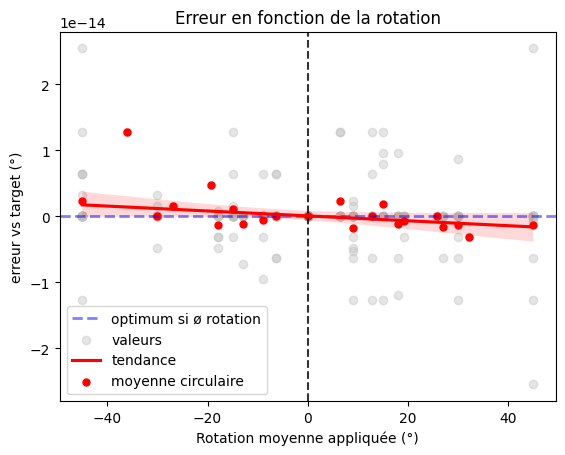

In [41]:

x = (df_radian.groupby("mean_rotation")["errors_to_target"].apply(np.mean).reset_index().sort_values("mean_rotation"))
x = np.rad2deg(x)

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="blue", linestyle="--", label= "optimum si ø rotation", alpha = 0.5, linewidth =2)   

sns.regplot(x=np.rad2deg(df_radian["mean_rotation"]), y=np.rad2deg(df_radian["errors_to_target"]), data=df_radian, color = "silver", label = "valeurs", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendance"})
plt.scatter(x["mean_rotation"], x["errors_to_target"], color="red", s=25, label="moyenne circulaire")

plt.xlabel("Rotation moyenne appliquée (°)")
plt.ylabel("erreur vs target (°)")
plt.title("Erreur en fonction de la rotation")
plt.legend()
plt.show()

In [42]:
opt_curve

,mean_rotation,y_optimal
0,-0.785398,-0.785398
1,-0.628319,-0.667492
2,-0.523599,-0.551376
3,-0.471239,-0.510219
4,-0.336599,-0.975421
5,-0.314159,-0.530993
6,-0.261799,-0.498304
7,-0.224399,-0.411558
8,-0.157080,-0.587790
9,-0.112200,-0.192142


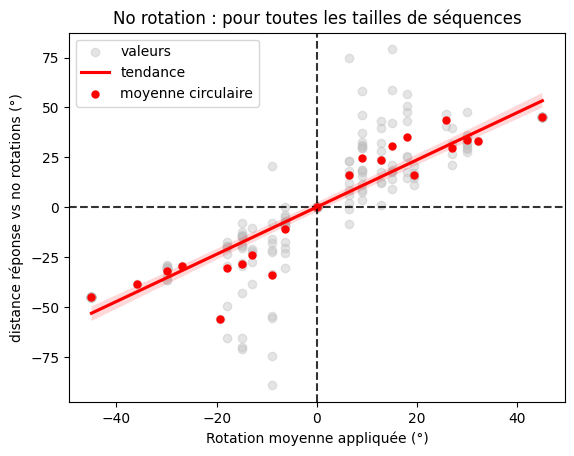

In [46]:
x = (df_radian.groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation"))
x = np.rad2deg(x)

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   
sns.regplot(x=df_radian["mean_rotation"].apply(np.rad2deg), y=df_radian["error_wo_rotation"].apply(np.rad2deg), data=df_radian, color = "silver", label = "valeurs", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendance"})
borne = x["mean_rotation"]
# plt.plot(opt_curve["mean_rotation"].apply(np.rad2deg), opt_curve["y_optimal"].apply(np.rad2deg),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
plt.scatter(x["mean_rotation"], x["error_wo_rotation"], color="red", s=25, label="moyenne circulaire")
# plt.plot(opt_curve.apply(np.rad2deg))
plt.xlabel("Rotation moyenne appliquée (°)")
plt.ylabel("distance réponse vs no rotations (°)")
plt.title("No rotation : pour toutes les tailles de séquences")
plt.legend()
plt.show()

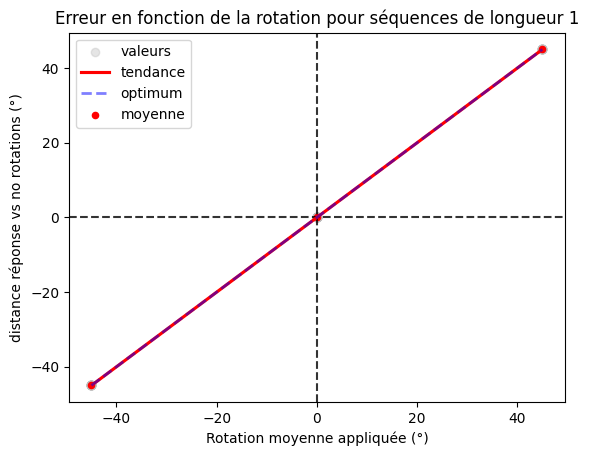

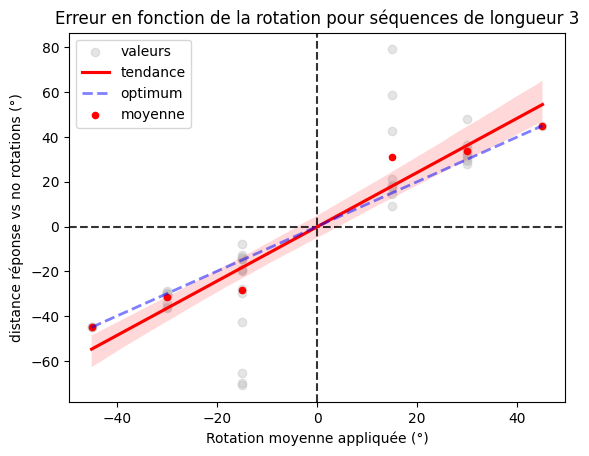

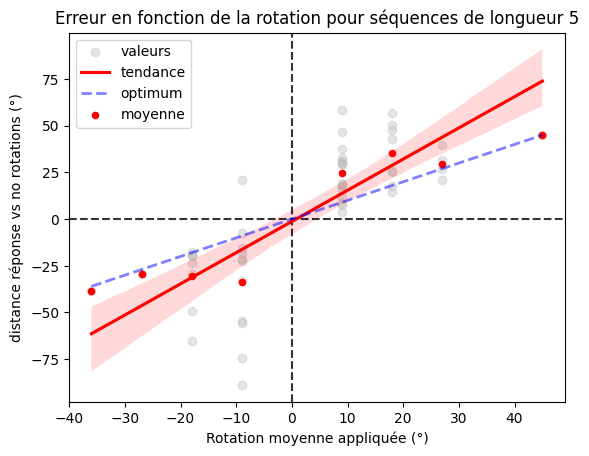

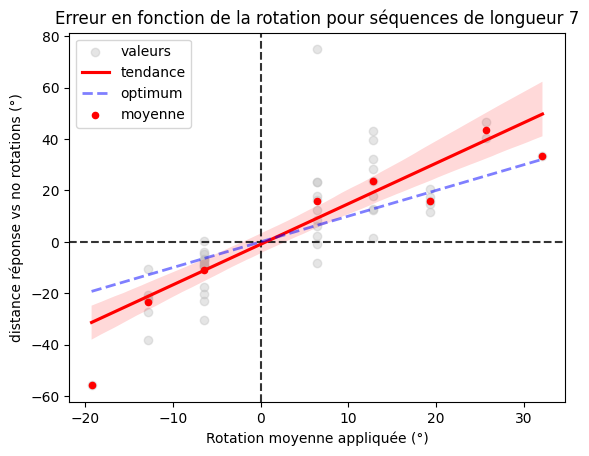

In [47]:
for seqlen in [1,3,5,7] :
    plt.figure()
    x = (df_radian[df_radian["length of sequence"]==seqlen].groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation"))
    x = np.rad2deg(x)

    plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
    plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

    borne = x["mean_rotation"]
    sns.regplot(x=np.rad2deg(df_radian[df_radian["length of sequence"]==seqlen]["mean_rotation"]), y=np.rad2deg(df_radian[df_radian["length of sequence"]==seqlen]["error_wo_rotation"]), data=df_radian[df_radian["length of sequence"]==seqlen], color = "silver", label = "valeurs", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendance"})
    plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
    
    # plt.plot(opt_curve["mean_rotation"].apply(np.rad2deg), opt_curve["y_optimal"].apply(np.rad2deg),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
    plt.scatter(x["mean_rotation"], x["error_wo_rotation"], color="red", s=20, label="moyenne")

    plt.xlabel("Rotation moyenne appliquée (°)")
    plt.ylabel("distance réponse vs no rotations (°)")
    plt.title(f"Erreur en fonction de la rotation pour séquences de longueur {seqlen}")
    plt.legend()
    plt.show()